# EN3160 - Computer Vision and Image Processing
## Assignment 03: Neural Networks

**Name:** K. D. Manatunga

**Index Number:** 230395T

**GitHub:** https://github.com/KaveeDiv23/Computer-Vision-Assignment-03

In [5]:
from pathlib import Path
from copy import deepcopy
import random
import time
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

from torchvision import datasets, transforms, models
from torchvision.models import ResNet18_Weights
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display, Markdown

In [6]:
SEED = 42
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PIN_MEMORY = DEVICE.type == "cuda"
NUM_WORKERS = 0

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
print("PyTorch:", torch.__version__)
print("TorchVision:", torchvision.__version__)
print("Device:", DEVICE)

PyTorch: 2.11.0+cu128
TorchVision: 0.26.0+cu128
Device: cuda


In [7]:
def make_loaders(train_data, test_data, batch_size):
    common = dict(num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
    train = DataLoader(
        train_data, batch_size=batch_size, shuffle=True,
        generator=torch.Generator().manual_seed(SEED), **common
    )
    train_eval = DataLoader(train_data, batch_size=256, shuffle=False, **common)
    test = DataLoader(test_data, batch_size=256, shuffle=False, **common)
    return train, train_eval, test


def plot_history(history, title, eval_name="Test"):
    df = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    for ax, metric, label in zip(
        axes, ["loss", "acc"], ["Cross-Entropy Loss", "Accuracy (%)"]
    ):
        ax.plot(df["epoch"], df[f"train_{metric}"], "-o", label="Training")
        ax.plot(df["epoch"], df[f"eval_{metric}"], "-o", label=eval_name)
        ax.set(xlabel="Epoch", ylabel=label, title=label)
        ax.set_xticks(df["epoch"])
        ax.legend()
        ax.grid(alpha=0.3)

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def show_cm(y_true, y_pred, class_names, title):
    cm = confusion_matrix(
        y_true, y_pred, labels=range(len(class_names))
    )
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay(
        cm, display_labels=class_names
    ).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()
    return cm

##### Question 1 - Fully Connected Neural Network

###### Methodology

The provided single-layer network was extended by introducing a
hidden layer containing 100 sigmoid neurons. Each 32 × 32 RGB
CIFAR-10 image was flattened into a 3072-dimensional input vector.
The network produces 10 output logits corresponding to the CIFAR-10
classes.

Multiclass cross-entropy replaced the original mean squared error
loss. Forward propagation, gradient computation, and parameter
updates were implemented manually. The network was trained for
10 epochs and evaluated using training and test accuracy.

In [8]:
q1_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,)*3, (0.5,)*3)
])

cifar_train = datasets.CIFAR10(
    DATA_DIR, train=True, download=True, transform=q1_transform
)
cifar_test = datasets.CIFAR10(
    DATA_DIR, train=False, download=True, transform=q1_transform
)
q1_train, q1_train_eval, q1_test = make_loaders(
    cifar_train, cifar_test, batch_size=50
)

print("Training samples:", len(cifar_train))
print("Test samples:", len(cifar_test))
print("Classes:", cifar_train.classes)

100%|██████████| 170M/170M [1:00:18<00:00, 47.1kB/s] 


Training samples: 50000
Test samples: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [9]:
DIN, HIDDEN, K = 3072, 100, 10
Q1_EPOCHS, Q1_LR, Q1_DECAY = 10, 0.1, 0.9

set_seed()

w1 = torch.randn(DIN, HIDDEN, device=DEVICE) * np.sqrt(2/(DIN+HIDDEN))
b1 = torch.zeros(HIDDEN, device=DEVICE)
w2 = torch.randn(HIDDEN, K, device=DEVICE) * np.sqrt(2/(HIDDEN+K))
b2 = torch.zeros(K, device=DEVICE)
q1_params = [w1, b1, w2, b2]

def dense_forward(x, params):
    w1, b1, w2, b2 = params
    h = torch.sigmoid(x @ w1 + b1)
    return h, h @ w2 + b2

def manual_backward(x, y, params):
    w1, b1, w2, b2 = params; h, z = dense_forward(x, params)
    log_probs = z - torch.logsumexp(z, dim=1, keepdim=True)
    loss = -log_probs[torch.arange(len(y), device=y.device), y].mean()
    d2 = log_probs.exp()
    d2[torch.arange(len(y), device=y.device), y] -= 1
    d2 /= len(y)
    dw2, db2 = h.T @ d2, d2.sum(0)
    d1 = (d2 @ w2.T) * h * (1-h)
    dw1, db1 = x.T @ d1, d1.sum(0)

    return loss, (dw1, db1, dw2, db2)

print("W1:", w1.shape, "W2:", w2.shape)

W1: torch.Size([3072, 100]) W2: torch.Size([100, 10])


In [10]:
x = torch.randn(4, 5)
y = torch.tensor([0, 1, 0, 1])
p = [torch.randn(5, 3), torch.zeros(3),
     torch.randn(3, 2), torch.zeros(2)]

loss, grads = manual_backward(x, y, p)
p_auto = [v.clone().requires_grad_() for v in p]
_, logits = dense_forward(x, p_auto)
auto_grads = torch.autograd.grad(F.cross_entropy(logits, y), p_auto)

error = max((a-b).abs().max().item() for a, b in zip(grads, auto_grads))
print(f"Maximum gradient difference: {error:.2e}")
assert error < 1e-5

Maximum gradient difference: 2.98e-08


In [11]:
@torch.no_grad()
def evaluate_dense(loader, params):
    total_loss, correct, count = 0.0, 0, 0

    for images, labels in loader:
        x = images.to(DEVICE).flatten(1)
        y = labels.to(DEVICE)
        _, logits = dense_forward(x, params)

        total_loss += F.cross_entropy(logits, y, reduction="sum").item()
        correct += (logits.argmax(1) == y).sum().item()
        count += len(y)

    return total_loss/count, 100*correct/count

In [12]:
q1_history = []
lr = Q1_LR

for epoch in range(1, Q1_EPOCHS+1):
    for images, labels in q1_train:
        x = images.to(DEVICE).flatten(1)
        y = labels.to(DEVICE)
        with torch.no_grad():
            _, grads = manual_backward(x, y, q1_params)
            for param, grad in zip(q1_params, grads):
                param -= lr * grad

    train_loss, train_acc = evaluate_dense(q1_train_eval, q1_params)
    test_loss, test_acc = evaluate_dense(q1_test, q1_params)

    q1_history.append({
        "epoch": epoch, "train_loss": train_loss,
        "train_acc": train_acc, "eval_loss": test_loss,
        "eval_acc": test_acc
    })
    lr *= Q1_DECAY

q1_df = pd.DataFrame(q1_history)
display(q1_df.round(3))

,epoch,train_loss,train_acc,eval_loss,eval_acc
0,1,1.685,41.588,1.702,41.05
1,2,1.621,44.368,1.653,42.36
2,3,1.571,46.154,1.624,43.86
3,4,1.523,47.782,1.589,45.41
4,5,1.485,49.304,1.569,45.86
5,6,1.455,50.336,1.549,46.69
6,7,1.446,50.224,1.555,46.09
7,8,1.405,51.970,1.528,47.30
8,9,1.387,52.732,1.523,47.36
9,10,1.364,53.548,1.511,47.75


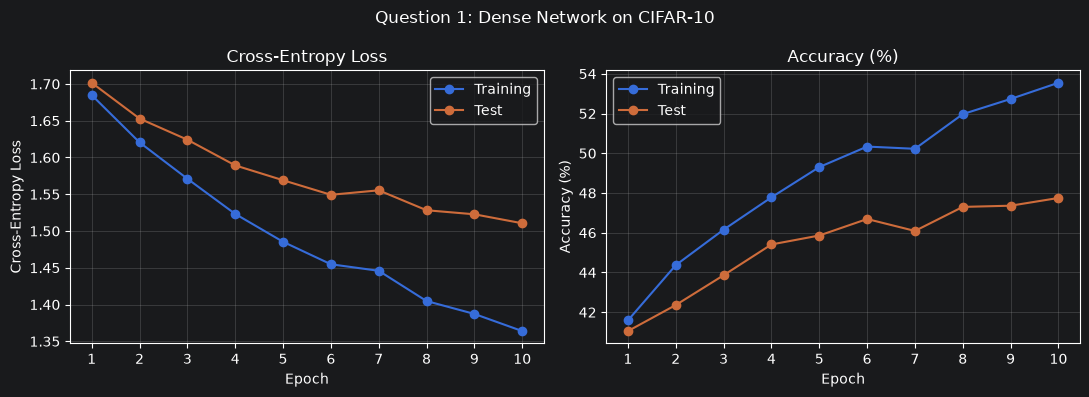

In [13]:
plot_history(q1_history, "Question 1: Dense Network on CIFAR-10")

In [14]:
q1_final = q1_df.iloc[-1]
q1_gap = q1_final["train_acc"] - q1_final["eval_acc"]

display(Markdown(
    f"**Results:** After 10 epochs, the network achieved a training "
    f"accuracy of **{q1_final['train_acc']:.2f}%** and a test accuracy "
    f"of **{q1_final['eval_acc']:.2f}%**. The training–test accuracy "
    f"gap was **{q1_gap:.2f} percentage points**."
))

**Results:** After 10 epochs, the network achieved a training accuracy of **53.55%** and a test accuracy of **47.75%**. The training–test accuracy gap was **5.80 percentage points**.

### Discussion

The introduction of a sigmoid hidden layer enables the network to
model nonlinear relationships between the input features, unlike
the original single-layer linear classifier. Cross-entropy loss
provides an appropriate optimization objective for multiclass
classification.

However, the network operates on flattened images and does not
explicitly exploit spatial relationships between neighboring pixels.
This limits its ability to learn local image features compared with
convolutional neural networks.

The training and test loss curves are used to assess convergence,
while the difference between training and test accuracy indicates
the extent to which the learned model generalizes to unseen data.

##### Question 2 - Convolutional Neural Networks

###### Methodology

Two convolutional neural networks were implemented for handwritten
digit classification using MNIST. The first was a LeNet-5-style
architecture containing convolutional layers, average pooling, tanh
activations, and fully connected layers. The second was a modern CNN
containing three convolutional layers, batch normalization, ReLU
activations, max pooling, and dropout.

Both models were trained for 10 epochs using the same dataset,
preprocessing, batch size, optimizer, and learning rate. Performance
was evaluated using training and test accuracy, cross-entropy loss
curves, and test-set confusion matrices.

In [ ]:
Q2_EPOCHS, Q2_BATCH, Q2_LR = 10, 128, 0.001
mnist_transform = transforms.Compose([
    transforms.Pad(2),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

mnist_train = datasets.MNIST(
    DATA_DIR, train=True, download=True, transform=mnist_transform
)
mnist_test = datasets.MNIST(
    DATA_DIR, train=False, download=True, transform=mnist_transform
)

print("Training samples:", len(mnist_train))
print("Test samples:", len(mnist_test))
print("Image shape:", mnist_train[0][0].shape)

##### 2.1 LeNet-5 Architecture

LeNet-5 is a classical convolutional neural network designed for
handwritten character recognition. The implemented architecture uses
convolutional layers for feature extraction, average pooling for
spatial downsampling, tanh activation functions, and fully connected
layers for classification.

A standard modern 10-class output layer is used instead of the
original LeNet-5 output formulation.

In [ ]:
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, 5), nn.Tanh(), nn.AvgPool2d(2),
            nn.Conv2d(6, 16, 5), nn.Tanh(), nn.AvgPool2d(2),
            nn.Conv2d(16, 120, 5), nn.Tanh()
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(120, 84),nn.Tanh(), nn.Linear(84, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

lenet_check = LeNet5()
print("Output shape:", lenet_check(torch.zeros(2, 1, 32, 32)).shape)
print("Parameters:", sum(p.numel() for p in lenet_check.parameters()))

##### 2.2 Modern CNN Architecture

The modern CNN contains three convolutional layers with batch
normalization, ReLU activation, max pooling, and dropout.

Batch normalization helps stabilize training, ReLU provides
nonlinearity, and dropout provides regularization. Global average
pooling reduces the number of parameters needed for classification.

In [ ]:
class ModernCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Dropout2d(0.10),

            nn.Conv2d(32, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Dropout2d(0.15),

            nn.Conv2d(64, 128, 3, padding=1, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
            nn.Dropout2d(0.20),

            nn.AdaptiveAvgPool2d(1)
        )
        self.classifier = nn.Linear(128, 10)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))


modern_check = ModernCNN()
print("Output shape:", modern_check(torch.zeros(2, 1, 32, 32)).shape)
print("Parameters:", sum(p.numel() for p in modern_check.parameters()))

In [ ]:
def train_epoch(model, loader, optimizer, frozen=False):
    if frozen:
        model.eval()
        model.fc.train()
    else:
        model.train()

    total_loss, correct, count = 0.0, 0, 0

    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = F.cross_entropy(logits, y)
        loss.backward(); optimizer.step()
        total_loss += loss.item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
        count += len(y)
    return total_loss/count, 100*correct/count


@torch.no_grad()
def evaluate_model(model, loader, predictions=False):
    model.eval()
    total_loss, correct, count = 0.0, 0, 0
    y_true, y_pred = [], []

    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits = model(x)
        pred = logits.argmax(1)
        total_loss += F.cross_entropy(logits, y, reduction="sum").item()
        correct += (pred == y).sum().item()
        count += len(y)
        if predictions:
            y_true.extend(y.cpu().tolist())
            y_pred.extend(pred.cpu().tolist())

    result = (total_loss/count, 100*correct/count)
    return (*result, y_true, y_pred) if predictions else result

def run_mnist(model_class):
    set_seed()
    train, train_eval, test = make_loaders(
        mnist_train, mnist_test, Q2_BATCH
    )

    model = model_class().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=Q2_LR)
    history = []
    for epoch in range(1, Q2_EPOCHS+1):
        train_epoch(model, train, optimizer)
        tr_loss, tr_acc = evaluate_model(model, train_eval)
        te_loss, te_acc = evaluate_model(model, test)
        history.append({
            "epoch": epoch, "train_loss": tr_loss,
            "train_acc": tr_acc, "eval_loss": te_loss,
            "eval_acc": te_acc
        })
    _, _, y_true, y_pred = evaluate_model(
        model, test, predictions=True
    )
    return model, history, y_true, y_pred

In [ ]:
lenet, lenet_history, lenet_true, lenet_pred = run_mnist(LeNet5)
display(pd.DataFrame(lenet_history).round(3))
plot_history(lenet_history, "LeNet-5 on MNIST")
lenet_cm = show_cm(
    lenet_true, lenet_pred, [str(i) for i in range(10)],
    "LeNet-5 Test Confusion Matrix"
)